In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import seaborn as sns
pd.set_option('display.max_columns', None)



/kaggle/input/competitions/playground-series-s6e11/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e11/train.csv
/kaggle/input/competitions/playground-series-s6e11/test.csv


In [2]:
train = pd.read_csv('/kaggle/input/competitions/playground-series-s6e11/train.csv')
test = pd.read_csv('/kaggle/input/competitions/playground-series-s6e11/test.csv')
sub = pd.read_csv('/kaggle/input/competitions/playground-series-s6e11/sample_submission.csv')

print(train.shape)
print(test.shape)
print(sub.shape)

(699960, 26)
(299984, 25)
(299984, 2)


In [3]:
train.head(2)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0


In [4]:
train.duplicated().sum()

np.int64(0)

In [5]:
res = pd.DataFrame()
res['miss'] = train.isnull().sum()
res['dtype'] = train.dtypes
res['nunique'] = train.nunique()
res

,miss,dtype,nunique
id,0,int64,699960
amount_usd,0,float64,13387
hours_since_last_txn,0,float64,3633
txn_count_last_24h,0,int64,12
distance_from_home_km,0,float64,4365
card_age_months,0,int64,49
customer_age,0,int64,64
account_balance_usd,0,float64,43317
cvv_retry_count,0,int64,4
velocity_score,0,float64,666


In [6]:
bool_cols = train.select_dtypes(include = 'bool').columns
print('bool columns are: ', bool_cols)

for c in bool_cols:
    train[c] = train[c].astype(int)


bool columns are:  Index(['is_foreign_transaction', 'is_new_merchant', 'used_vpn',
       'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='object')


In [7]:
cat_cols = train.select_dtypes(include = 'object').columns
print('categorical columns are: ', cat_cols)


categorical columns are:  Index(['merchant_category', 'card_type', 'auth_method', 'channel',
       'device_type'],
      dtype='object')


In [8]:
num_cols = train.select_dtypes(include = 'number').columns
print('numeric columns are: ', num_cols)


numeric columns are:  Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='object')


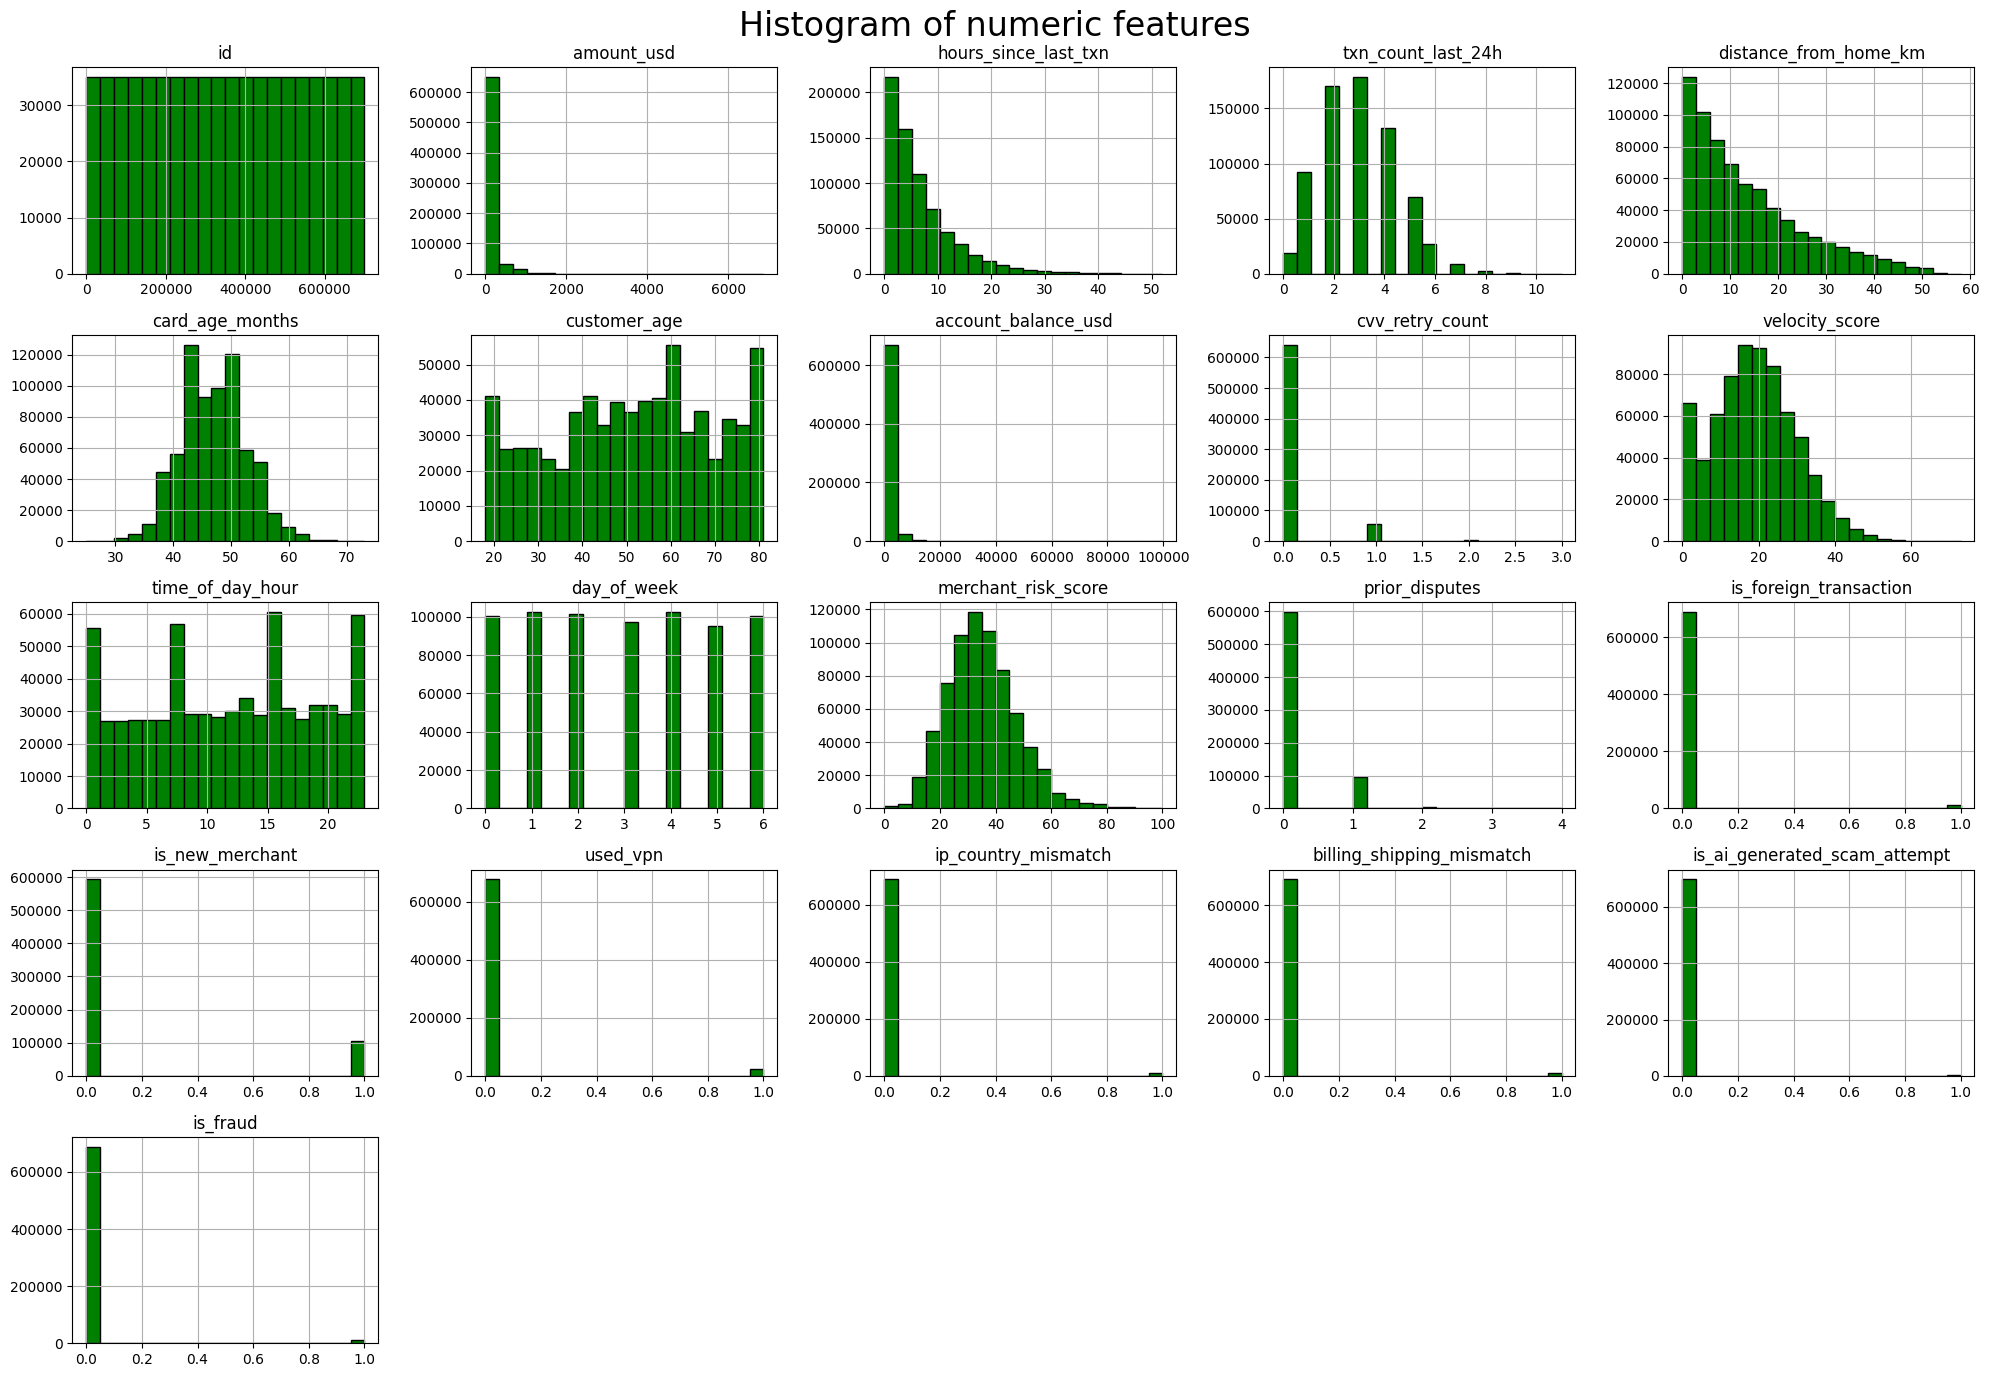

In [9]:

train[num_cols].hist(layout=(5, 5), bins=20, figsize=(20, 14), color='green', edgecolor='black')
plt.suptitle('Histogram of numeric features', fontsize = 24)
plt.tight_layout()
plt.show()

In [10]:
target = 'is_fraud'
cor = train[num_cols].corr()[target].reset_index().sort_values(by = target,ascending = False)
cor.head(30)['index'].values

array(['is_fraud', 'cvv_retry_count', 'ip_country_mismatch',
       'merchant_risk_score', 'is_foreign_transaction', 'velocity_score',
       'is_new_merchant', 'billing_shipping_mismatch', 'used_vpn',
       'is_ai_generated_scam_attempt', 'txn_count_last_24h',
       'customer_age', 'prior_disputes', 'amount_usd', 'day_of_week',
       'distance_from_home_km', 'account_balance_usd', 'card_age_months',
       'time_of_day_hour', 'id', 'hours_since_last_txn'], dtype=object)

In [11]:
train.cvv_retry_count.value_counts()

cvv_retry_count
0    642088
1     55942
2      1905
3        25
Name: count, dtype: int64

### How Does Fraud Risk Change Across Numerical Features?


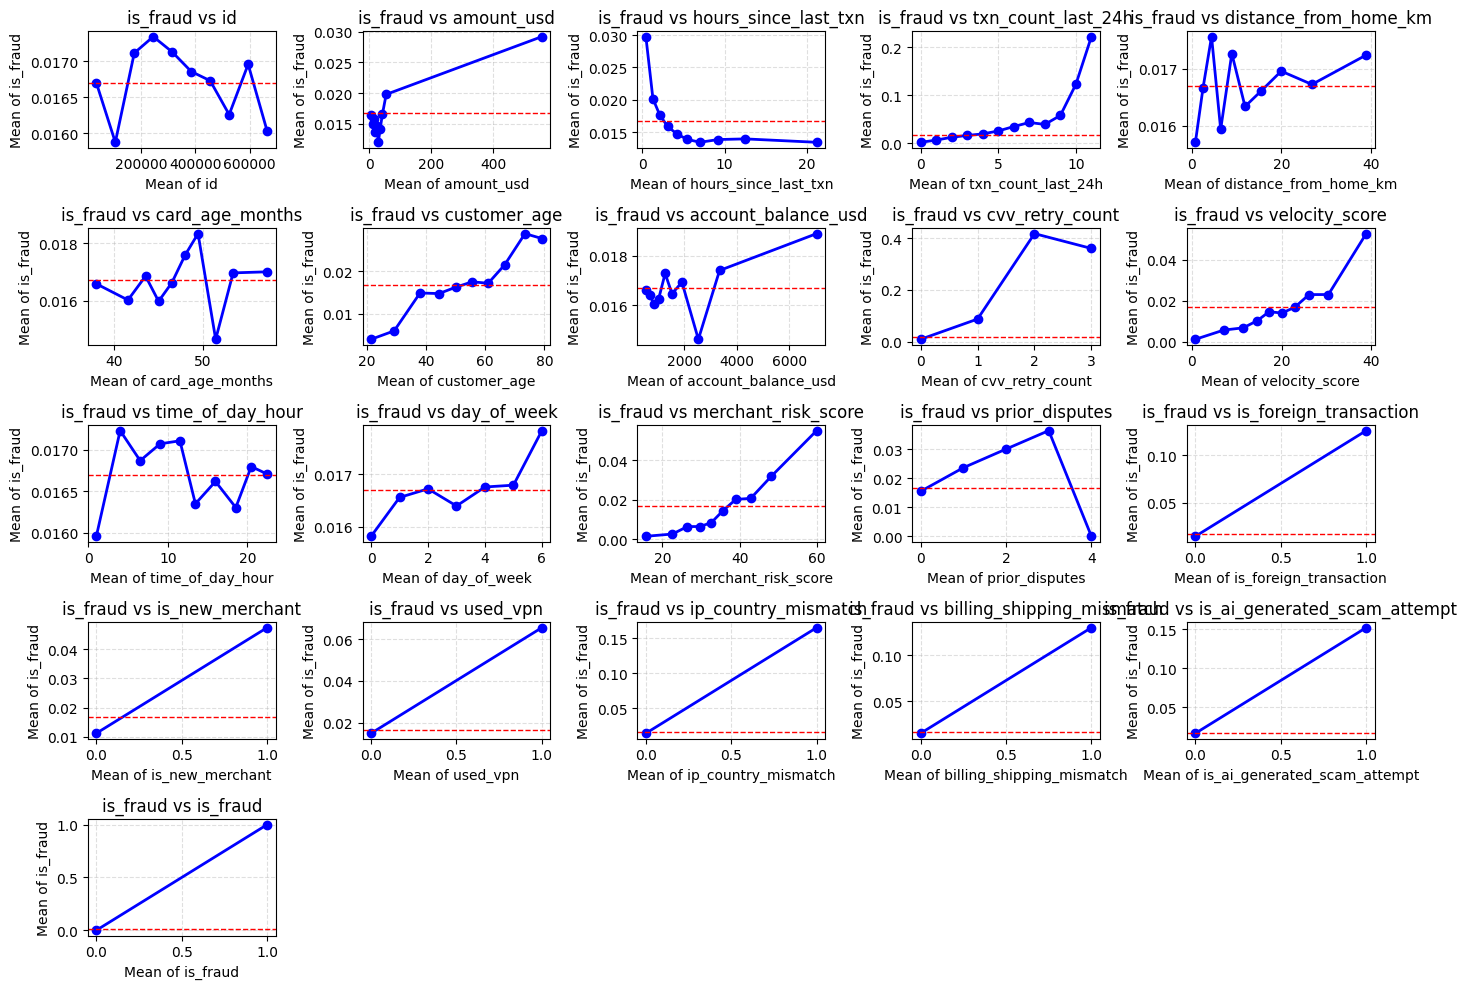

In [12]:
# Calculate rows needed for a 2-column grid layout

n_features = len(num_cols)

fig, axes = plt.subplots(5, 5, figsize=(14, 10))
axes = axes.flatten()  # Flatten into 1D array for easy indexing

for i, col in enumerate(num_cols):
    
    discrete = train[col].nunique() <= 16
    
    train["bucket"] = train[col] if discrete else pd.qcut(train[col], q=10, duplicates="drop")
    bin_stats = (
        train.groupby("bucket", observed=False)
        .agg(feature_mean=(col, "mean"), target_mean=(target, "mean"))
        .reset_index()
    )

    # Plotting using the axis object explicitly
    axes[i].plot(
        bin_stats["feature_mean"],
        bin_stats["target_mean"],
        marker="o",
        color="blue",
        linewidth=2,
    )
    axes[i].axhline(train[target].mean(), color='r', linestyle='--', linewidth=1)
    axes[i].set_title(f"{target} vs {col}")
    axes[i].set_xlabel(f"Mean of {col}")
    axes[i].set_ylabel(f"Mean of {target}")
    axes[i].grid(True, linestyle="--", alpha=0.4)

# Hide any unused subplots in the grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()



### Numerical Feature Correlations

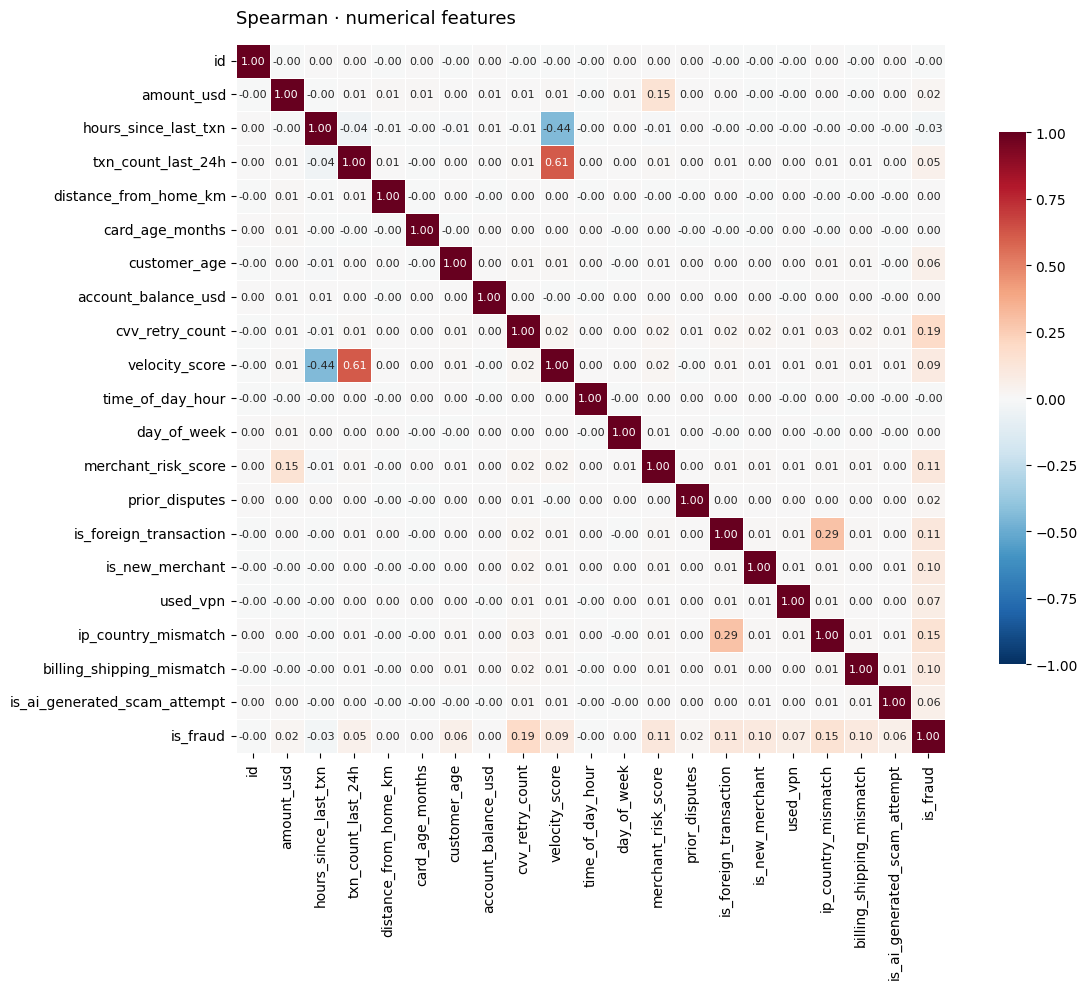

In [13]:
corr = train[num_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=.5, linecolor='white', square=True, annot=True,
            fmt='.2f', annot_kws={'size': 8}, cbar_kws={'shrink': .75}, ax=ax)
ax.set_title('Spearman · numerical features', loc='left', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

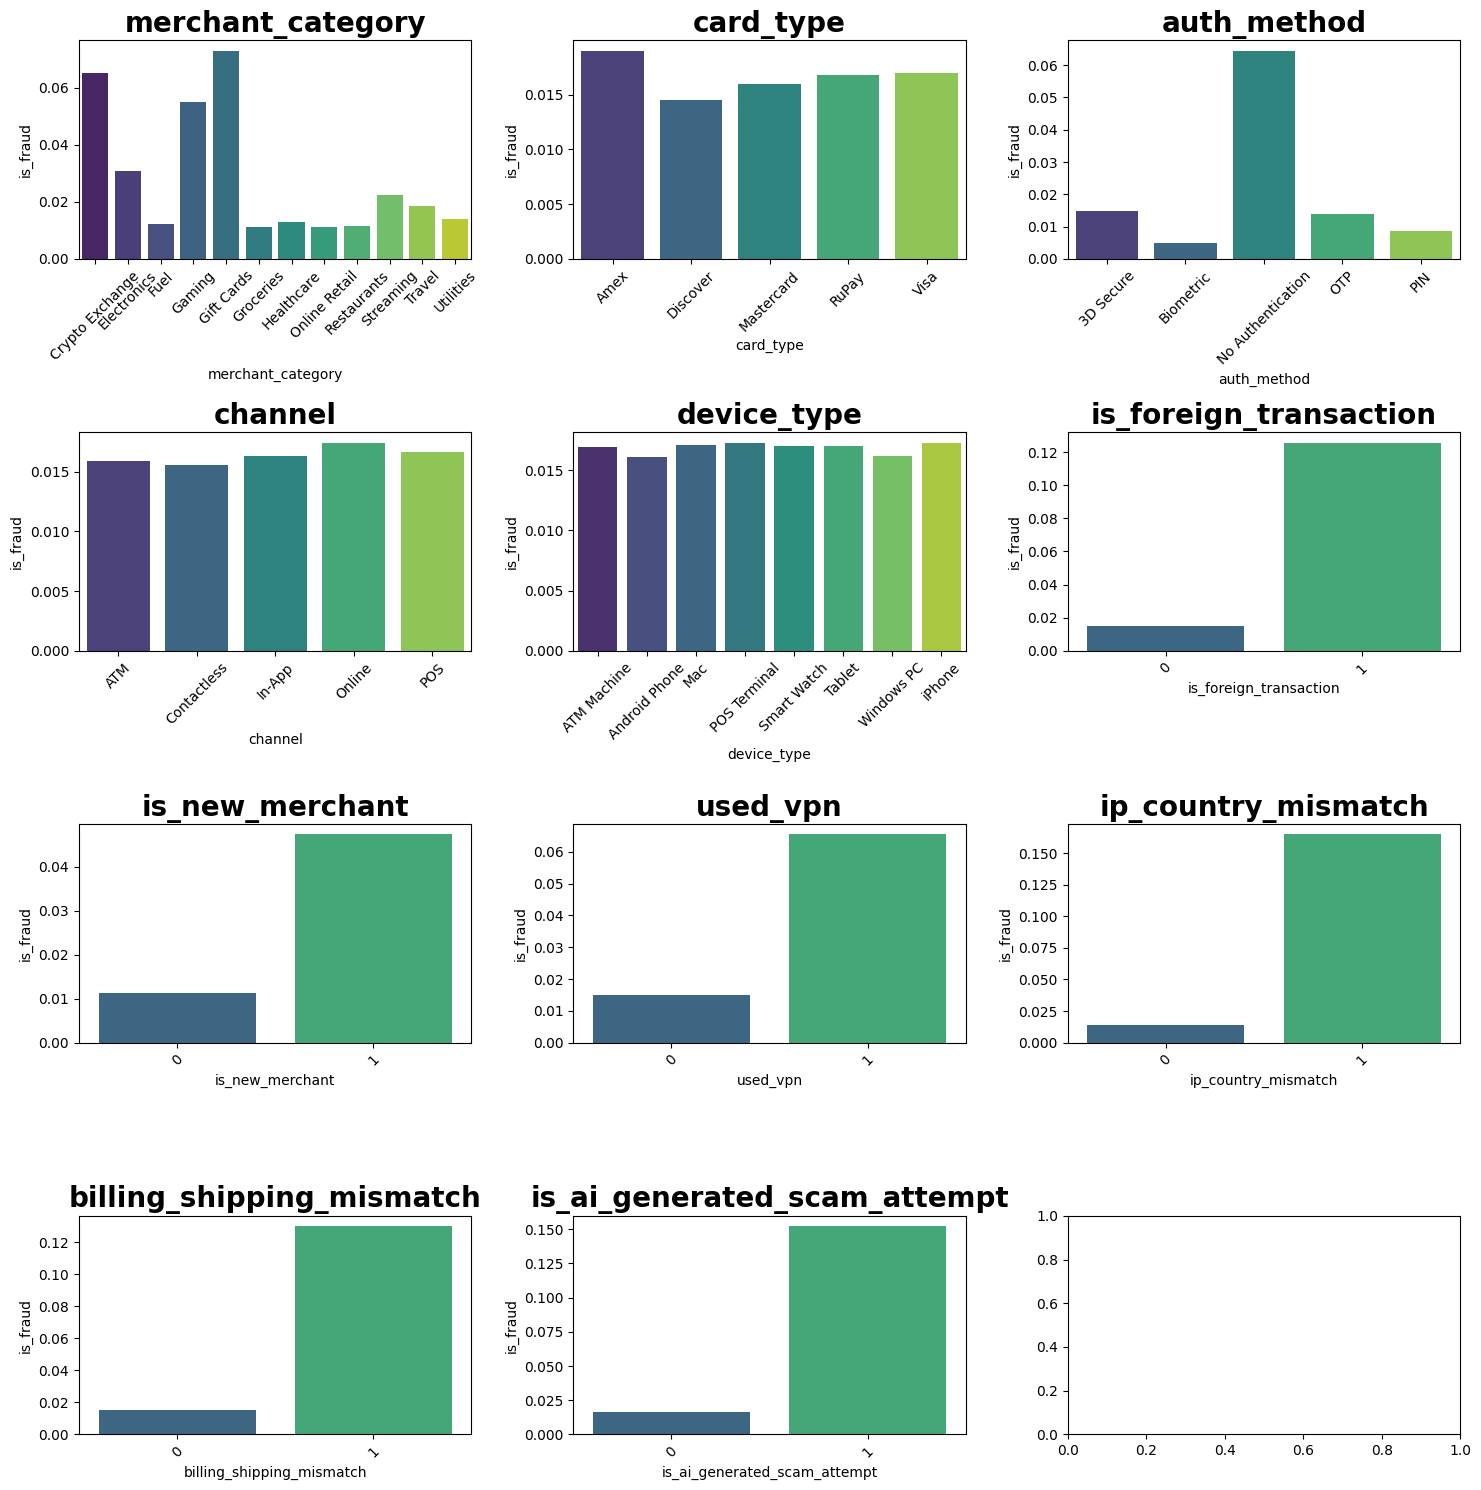

In [14]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 15))
axes = axes.flatten()  # Flatten the 2D array of axes into a 1D array for easier looping

# 4. Loop through features and plot target mean on each subplot
for i, col in enumerate(list(cat_cols) + list(bool_cols)):
    # Calculate the mean target value for each category
    mean_data = train.groupby(col)[target].mean().reset_index()
    
    # Generate the bar plot on the specific subplot axis
    sns.barplot(
        x=col, 
        y=target, 
        data=mean_data, 
        ax=axes[i], 
        palette="viridis", 
        hue=col, 
        legend=False
    )
    
    # Formatting adjustments for readability
    axes[i].set_title(col, fontsize=20, fontweight='bold')
    axes[i].tick_params(axis='x', labelrotation=45)

   
# 5. Clean layout formatting
plt.tight_layout()
plt.show()

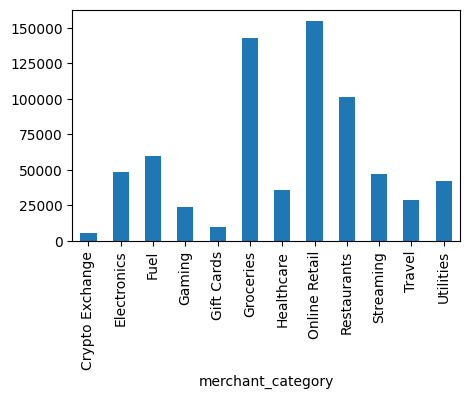

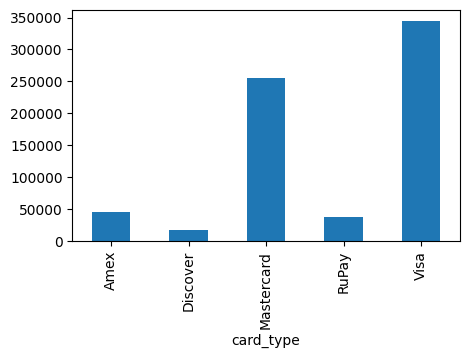

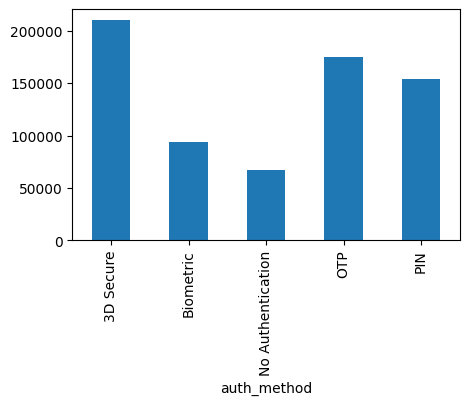

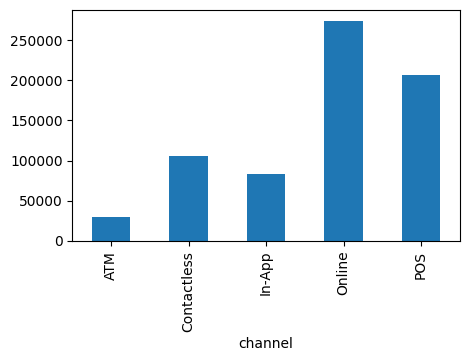

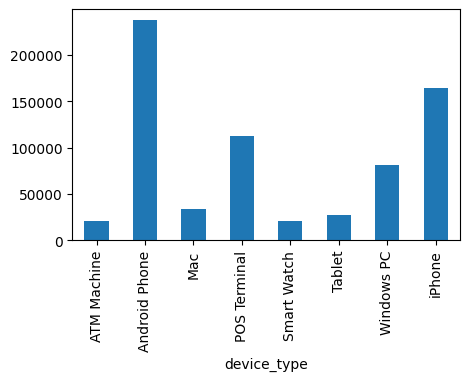

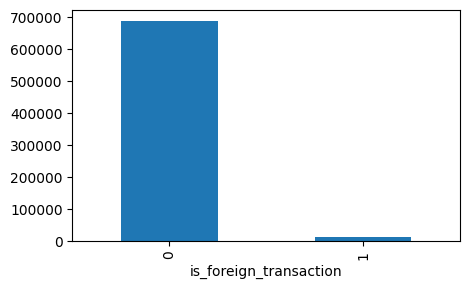

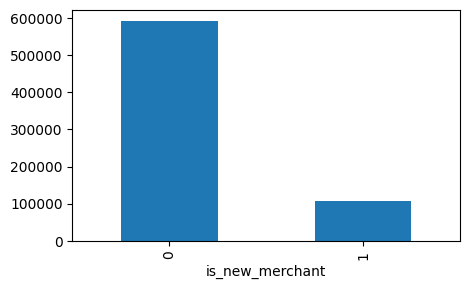

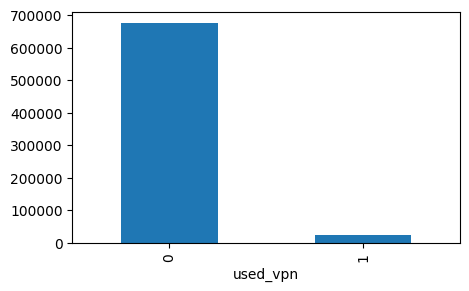

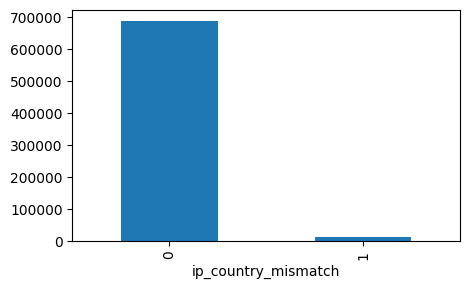

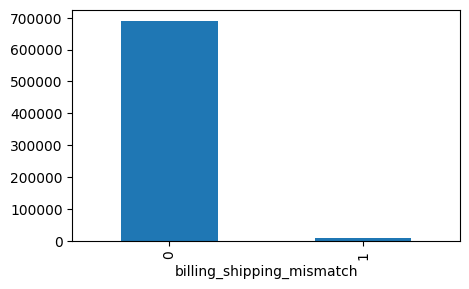

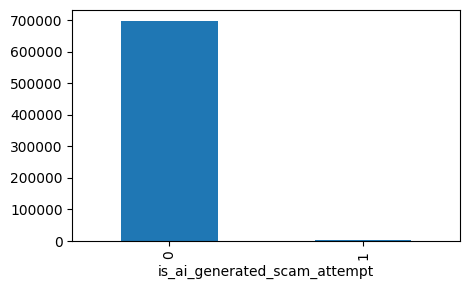

In [15]:
for c in list(cat_cols) + list(bool_cols) :
    train.groupby(c).size().plot(kind = 'bar', figsize = (5,3))
    plt.show()

In [16]:
train[target].value_counts()

is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64

In [17]:
scale_weight = 688271/11689
scale_weight

58.88194028573873

# FE

In [18]:
df = pd.concat([train,test]).reset_index(drop = True)
print(df.shape)

(999944, 27)


In [19]:
list(cat_cols) + list(bool_cols)

['merchant_category',
 'card_type',
 'auth_method',
 'channel',
 'device_type',
 'is_foreign_transaction',
 'is_new_merchant',
 'used_vpn',
 'ip_country_mismatch',
 'billing_shipping_mismatch',
 'is_ai_generated_scam_attempt']

In [20]:
from itertools import combinations

# ######################### Agg features   
main_cols = [ 'cvv_retry_count', 
       'merchant_risk_score', 'velocity_score', 'txn_count_last_24h']

ag_cols = list(cat_cols) + list(bool_cols)


col_list = ['is_foreign_transaction',
 'is_new_merchant',
 'used_vpn',
 'ip_country_mismatch',
 'billing_shipping_mismatch',
 'is_ai_generated_scam_attempt']

comb_cols = []
for col1, col2 in combinations(col_list, 2):
    # Generates names like 'A_B', 'A_C', 'B_C'
    new_col_name = col1+'_'+col2

    # Concatenate the strings with an optional separator (e.g., '-')
    df[new_col_name] = df[col1].astype(str) + "-" + df[col2].astype(str)
    comb_cols.append(new_col_name)
    


df['customer_age > 30'] = (df['customer_age'] > 30).astype(int)


df['amt/bal'] = df['amount_usd']/df['account_balance_usd']




for col in ag_cols + comb_cols:    
    fq_encode = df[col].value_counts(dropna= True, normalize = True).to_dict()   
    df[col+'_fq_enc'] = df[col].map(fq_encode)
    
for col_a in main_cols: 
    for col_b in ag_cols + comb_cols:
        df[col_a + '_' + col_b + '_mean'] = df.groupby(col_b)[col_a].transform('mean')    
        df[col_a + '_' + col_b + '_std'] = df.groupby(col_b)[col_a].transform('std')
        #df[col_a + '_' + col_b + '_median'] = df.groupby(col_b)[col_a].transform('median')


print(df.shape)
df.head()

(999944, 278)


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,bucket,is_foreign_transaction_is_new_merchant,is_foreign_transaction_used_vpn,is_foreign_transaction_ip_country_mismatch,is_foreign_transaction_billing_shipping_mismatch,is_foreign_transaction_is_ai_generated_scam_attempt,is_new_merchant_used_vpn,is_new_merchant_ip_country_mismatch,is_new_merchant_billing_shipping_mismatch,is_new_merchant_is_ai_generated_scam_attempt,used_vpn_ip_country_mismatch,used_vpn_billing_shipping_mismatch,used_vpn_is_ai_generated_scam_attempt,ip_country_mismatch_billing_shipping_mismatch,ip_country_mismatch_is_ai_generated_scam_attempt,billing_shipping_mismatch_is_ai_generated_scam_attempt,customer_age > 30,amt/bal,merchant_category_fq_enc,card_type_fq_enc,auth_method_fq_enc,channel_fq_enc,device_type_fq_enc,is_foreign_transaction_fq_enc,is_new_merchant_fq_enc,used_vpn_fq_enc,ip_country_mismatch_fq_enc,billing_shipping_mismatch_fq_enc,is_ai_generated_scam_attempt_fq_enc,is_foreign_transaction_is_new_merchant_fq_enc,is_foreign_transaction_used_vpn_fq_enc,is_foreign_transaction_ip_country_mismatch_fq_enc,is_foreign_transaction_billing_shipping_mismatch_fq_enc,is_foreign_transaction_is_ai_generated_scam_attempt_fq_enc,is_new_merchant_used_vpn_fq_enc,is_new_merchant_ip_country_mismatch_fq_enc,is_new_merchant_billing_shipping_mismatch_fq_enc,is_new_merchant_is_ai_generated_scam_attempt_fq_enc,used_vpn_ip_country_mismatch_fq_enc,used_vpn_billing_shipping_mismatch_fq_enc,used_vpn_is_ai_generated_scam_attempt_fq_enc,ip_country_mismatch_billing_shipping_mismatch_fq_enc,ip_country_mismatch_is_ai_generated_scam_attempt_fq_enc,billing_shipping_mismatch_is_ai_generated_scam_attempt_fq_enc,cvv_retry_count_merchant_category_mean,cvv_retry_count_merchant_category_std,cvv_retry_count_card_type_mean,cvv_retry_count_card_type_std,cvv_retry_count_auth_method_mean,cvv_retry_count_auth_method_std,cvv_retry_count_channel_mean,cvv_retry_count_channel_std,cvv_retry_count_device_type_mean,cvv_retry_count_device_type_std,cvv_retry_count_is_foreign_transaction_mean,cvv_retry_count_is_foreign_transaction_std,cvv_retry_count_is_new_merchant_mean,cvv_retry_count_is_new_merchant_std,cvv_retry_count_used_vpn_mean,cvv_retry_count_used_vpn_std,cvv_retry_count_ip_country_mismatch_mean,cvv_retry_count_ip_country_mismatch_std,cvv_retry_count_billing_shipping_mismatch_mean,cvv_retry_count_billing_shipping_mismatch_std,cvv_retry_count_is_ai_generated_scam_attempt_mean,cvv_retry_count_is_ai_generated_scam_attempt_std,cvv_retry_count_is_foreign_transaction_is_new_merchant_mean,cvv_retry_count_is_foreign_transaction_is_new_merchant_std,cvv_retry_count_is_foreign_transaction_used_vpn_mean,cvv_retry_count_is_foreign_transaction_used_vpn_std,cvv_retry_count_is_foreign_transaction_ip_country_mismatch_mean,cvv_retry_count_is_foreign_transaction_ip_country_mismatch_std,cvv_retry_count_is_foreign_transaction_billing_shipping_mismatch_mean,cvv_retry_count_is_foreign_transaction_billing_shipping_mismatch_std,cvv_retry_count_is_foreign_transaction_is_ai_generated_scam_attempt_mean,cvv_retry_count_is_foreign_transaction_is_ai_generated_scam_attempt_std,cvv_retry_count_is_new_merchant_used_vpn_mean,cvv_retry_count_is_new_merchant_used_vpn_std,cvv_retry_count_is_new_merchant_ip_country_mismatch_mean,cvv_retry_count_is_new_merchant_ip_country_mismatch_std,cvv_retry_count_is_new_merchant_billing_shipping_mismatch_mean,cvv_retry_count_is_new_merchant_billing_shipping_mismatch_std,cvv_retry_count_is_new_merchant_is_ai_generated_scam_attempt_mean,cvv_retry_count_is_new_merchant_is_ai_generated_scam_attempt_std,cvv_retry_count_used_vpn_ip_country_mismatch_me

In [21]:
digit_num_cols = ['amount_usd', 'distance_from_home_km', 'velocity_score','merchant_risk_score',
 'account_balance_usd','hours_since_last_txn']
for col in digit_num_cols:
    for k in range(-3, 3):
        new_col = f'{col}_digit{k}'
        df[new_col] = (df[col].fillna(0) // (10**k) % 10).astype('int8')

print(f"digit features: {len(digit_num_cols) * 8}")
print(f"df shape: {df.shape} | df shape: {df.shape}")

df.head()

digit features: 48
df shape: (999944, 314) | df shape: (999944, 314)


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,bucket,is_foreign_transaction_is_new_merchant,is_foreign_transaction_used_vpn,is_foreign_transaction_ip_country_mismatch,is_foreign_transaction_billing_shipping_mismatch,is_foreign_transaction_is_ai_generated_scam_attempt,is_new_merchant_used_vpn,is_new_merchant_ip_country_mismatch,is_new_merchant_billing_shipping_mismatch,is_new_merchant_is_ai_generated_scam_attempt,used_vpn_ip_country_mismatch,used_vpn_billing_shipping_mismatch,used_vpn_is_ai_generated_scam_attempt,ip_country_mismatch_billing_shipping_mismatch,ip_country_mismatch_is_ai_generated_scam_attempt,billing_shipping_mismatch_is_ai_generated_scam_attempt,customer_age > 30,amt/bal,merchant_category_fq_enc,card_type_fq_enc,auth_method_fq_enc,channel_fq_enc,device_type_fq_enc,is_foreign_transaction_fq_enc,is_new_merchant_fq_enc,used_vpn_fq_enc,ip_country_mismatch_fq_enc,billing_shipping_mismatch_fq_enc,is_ai_generated_scam_attempt_fq_enc,is_foreign_transaction_is_new_merchant_fq_enc,is_foreign_transaction_used_vpn_fq_enc,is_foreign_transaction_ip_country_mismatch_fq_enc,is_foreign_transaction_billing_shipping_mismatch_fq_enc,is_foreign_transaction_is_ai_generated_scam_attempt_fq_enc,is_new_merchant_used_vpn_fq_enc,is_new_merchant_ip_country_mismatch_fq_enc,is_new_merchant_billing_shipping_mismatch_fq_enc,is_new_merchant_is_ai_generated_scam_attempt_fq_enc,used_vpn_ip_country_mismatch_fq_enc,used_vpn_billing_shipping_mismatch_fq_enc,used_vpn_is_ai_generated_scam_attempt_fq_enc,ip_country_mismatch_billing_shipping_mismatch_fq_enc,ip_country_mismatch_is_ai_generated_scam_attempt_fq_enc,billing_shipping_mismatch_is_ai_generated_scam_attempt_fq_enc,cvv_retry_count_merchant_category_mean,cvv_retry_count_merchant_category_std,cvv_retry_count_card_type_mean,cvv_retry_count_card_type_std,cvv_retry_count_auth_method_mean,cvv_retry_count_auth_method_std,cvv_retry_count_channel_mean,cvv_retry_count_channel_std,cvv_retry_count_device_type_mean,cvv_retry_count_device_type_std,cvv_retry_count_is_foreign_transaction_mean,cvv_retry_count_is_foreign_transaction_std,cvv_retry_count_is_new_merchant_mean,cvv_retry_count_is_new_merchant_std,cvv_retry_count_used_vpn_mean,cvv_retry_count_used_vpn_std,cvv_retry_count_ip_country_mismatch_mean,cvv_retry_count_ip_country_mismatch_std,cvv_retry_count_billing_shipping_mismatch_mean,cvv_retry_count_billing_shipping_mismatch_std,cvv_retry_count_is_ai_generated_scam_attempt_mean,cvv_retry_count_is_ai_generated_scam_attempt_std,cvv_retry_count_is_foreign_transaction_is_new_merchant_mean,cvv_retry_count_is_foreign_transaction_is_new_merchant_std,cvv_retry_count_is_foreign_transaction_used_vpn_mean,cvv_retry_count_is_foreign_transaction_used_vpn_std,cvv_retry_count_is_foreign_transaction_ip_country_mismatch_mean,cvv_retry_count_is_foreign_transaction_ip_country_mismatch_std,cvv_retry_count_is_foreign_transaction_billing_shipping_mismatch_mean,cvv_retry_count_is_foreign_transaction_billing_shipping_mismatch_std,cvv_retry_count_is_foreign_transaction_is_ai_generated_scam_attempt_mean,cvv_retry_count_is_foreign_transaction_is_ai_generated_scam_attempt_std,cvv_retry_count_is_new_merchant_used_vpn_mean,cvv_retry_count_is_new_merchant_used_vpn_std,cvv_retry_count_is_new_merchant_ip_country_mismatch_mean,cvv_retry_count_is_new_merchant_ip_country_mismatch_std,cvv_retry_count_is_new_merchant_billing_shipping_mismatch_mean,cvv_retry_count_is_new_merchant_billing_shipping_mismatch_std,cvv_retry_count_is_new_merchant_is_ai_generated_scam_attempt_mean,cvv_retry_count_is_new_merchant_is_ai_generated_scam_attempt_std,cvv_retry_count_used_vpn_ip_country_mismatch_me

# Preprocessing

In [22]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()


for c in ['merchant_category',
 'card_type',
 'auth_method',
 'channel',
 'device_type'] + comb_cols:
    df[c] = le.fit_transform(df[c])

df.head(3)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,bucket,is_foreign_transaction_is_new_merchant,is_foreign_transaction_used_vpn,is_foreign_transaction_ip_country_mismatch,is_foreign_transaction_billing_shipping_mismatch,is_foreign_transaction_is_ai_generated_scam_attempt,is_new_merchant_used_vpn,is_new_merchant_ip_country_mismatch,is_new_merchant_billing_shipping_mismatch,is_new_merchant_is_ai_generated_scam_attempt,used_vpn_ip_country_mismatch,used_vpn_billing_shipping_mismatch,used_vpn_is_ai_generated_scam_attempt,ip_country_mismatch_billing_shipping_mismatch,ip_country_mismatch_is_ai_generated_scam_attempt,billing_shipping_mismatch_is_ai_generated_scam_attempt,customer_age > 30,amt/bal,merchant_category_fq_enc,card_type_fq_enc,auth_method_fq_enc,channel_fq_enc,device_type_fq_enc,is_foreign_transaction_fq_enc,is_new_merchant_fq_enc,used_vpn_fq_enc,ip_country_mismatch_fq_enc,billing_shipping_mismatch_fq_enc,is_ai_generated_scam_attempt_fq_enc,is_foreign_transaction_is_new_merchant_fq_enc,is_foreign_transaction_used_vpn_fq_enc,is_foreign_transaction_ip_country_mismatch_fq_enc,is_foreign_transaction_billing_shipping_mismatch_fq_enc,is_foreign_transaction_is_ai_generated_scam_attempt_fq_enc,is_new_merchant_used_vpn_fq_enc,is_new_merchant_ip_country_mismatch_fq_enc,is_new_merchant_billing_shipping_mismatch_fq_enc,is_new_merchant_is_ai_generated_scam_attempt_fq_enc,used_vpn_ip_country_mismatch_fq_enc,used_vpn_billing_shipping_mismatch_fq_enc,used_vpn_is_ai_generated_scam_attempt_fq_enc,ip_country_mismatch_billing_shipping_mismatch_fq_enc,ip_country_mismatch_is_ai_generated_scam_attempt_fq_enc,billing_shipping_mismatch_is_ai_generated_scam_attempt_fq_enc,cvv_retry_count_merchant_category_mean,cvv_retry_count_merchant_category_std,cvv_retry_count_card_type_mean,cvv_retry_count_card_type_std,cvv_retry_count_auth_method_mean,cvv_retry_count_auth_method_std,cvv_retry_count_channel_mean,cvv_retry_count_channel_std,cvv_retry_count_device_type_mean,cvv_retry_count_device_type_std,cvv_retry_count_is_foreign_transaction_mean,cvv_retry_count_is_foreign_transaction_std,cvv_retry_count_is_new_merchant_mean,cvv_retry_count_is_new_merchant_std,cvv_retry_count_used_vpn_mean,cvv_retry_count_used_vpn_std,cvv_retry_count_ip_country_mismatch_mean,cvv_retry_count_ip_country_mismatch_std,cvv_retry_count_billing_shipping_mismatch_mean,cvv_retry_count_billing_shipping_mismatch_std,cvv_retry_count_is_ai_generated_scam_attempt_mean,cvv_retry_count_is_ai_generated_scam_attempt_std,cvv_retry_count_is_foreign_transaction_is_new_merchant_mean,cvv_retry_count_is_foreign_transaction_is_new_merchant_std,cvv_retry_count_is_foreign_transaction_used_vpn_mean,cvv_retry_count_is_foreign_transaction_used_vpn_std,cvv_retry_count_is_foreign_transaction_ip_country_mismatch_mean,cvv_retry_count_is_foreign_transaction_ip_country_mismatch_std,cvv_retry_count_is_foreign_transaction_billing_shipping_mismatch_mean,cvv_retry_count_is_foreign_transaction_billing_shipping_mismatch_std,cvv_retry_count_is_foreign_transaction_is_ai_generated_scam_attempt_mean,cvv_retry_count_is_foreign_transaction_is_ai_generated_scam_attempt_std,cvv_retry_count_is_new_merchant_used_vpn_mean,cvv_retry_count_is_new_merchant_used_vpn_std,cvv_retry_count_is_new_merchant_ip_country_mismatch_mean,cvv_retry_count_is_new_merchant_ip_country_mismatch_std,cvv_retry_count_is_new_merchant_billing_shipping_mismatch_mean,cvv_retry_count_is_new_merchant_billing_shipping_mismatch_std,cvv_retry_count_is_new_merchant_is_ai_generated_scam_attempt_mean,cvv_retry_count_is_new_merchant_is_ai_generated_scam_attempt_std,cvv_retry_count_used_vpn_ip_country_mismatch_me

# Model development

In [23]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold, StratifiedKFold

train = df[:len(train)]
test = df[-len(test):]
print(train.shape)
print(test.shape)


X_train = train.drop(['id','is_fraud'], axis = 1)
X_test = test.drop(['id','is_fraud'], axis = 1)

y_train = train[target]
print(X_train.shape)
print(X_test.shape)


(699960, 314)
(299984, 314)
(699960, 312)
(299984, 312)


In [24]:
from sklearn.preprocessing import TargetEncoder

kf = KFold(n_splits = 5, shuffle = True, random_state = 2025)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=11)

Folds = 5

preds_lgb = np.zeros(len(sub))
preds_xgb = np.zeros(len(sub))
oof_lgb = np.zeros(len(X_train))
oof_xgb = np.zeros(len(X_train))

TARGET_ENCODE_COLS = cat_cols

scale_weight = 688271/11689


#LGBM
for i, (idxt, idxv) in enumerate(skf.split(X_train, y_train)):

    print('Fold:', i+1)
    print('*'* 50)

    X_trn, X_val = X_train.iloc[idxt], X_train.iloc[idxv]
    y_trn, y_val = y_train.iloc[idxt], y_train.iloc[idxv]
    X_test_fold = X_test.copy()


    #     # Triple Sklearn Target Encoders (Auto, Strict 10, and Massive 100)
    # te_auto = TargetEncoder(shuffle=True, cv=Folds, smooth='auto', random_state=42)
    # te_10   = TargetEncoder(shuffle=True, cv=Folds, smooth=10.0, random_state=42)
    # te_100  = TargetEncoder(shuffle=True, cv=Folds, smooth=100.0, random_state=42)
    
    # X_train_enc_auto = te_auto.fit_transform(X_trn[TARGET_ENCODE_COLS], y_trn)
    # X_valid_enc_auto = te_auto.transform(X_val[TARGET_ENCODE_COLS])
    # X_test_enc_auto  = te_auto.transform(X_test_fold[TARGET_ENCODE_COLS])

    # X_train_enc_10 = te_10.fit_transform(X_trn[TARGET_ENCODE_COLS], y_trn)
    # X_valid_enc_10 = te_10.transform(X_val[TARGET_ENCODE_COLS])
    # X_test_enc_10  = te_10.transform(X_test_fold[TARGET_ENCODE_COLS])

    # X_train_enc_100 = te_100.fit_transform(X_trn[TARGET_ENCODE_COLS], y_trn)
    # X_valid_enc_100 = te_100.transform(X_val[TARGET_ENCODE_COLS])
    # X_test_enc_100  = te_100.transform(X_test_fold[TARGET_ENCODE_COLS])
    
    # for i, col in enumerate(TARGET_ENCODE_COLS):
    #     # Auto smoothing TE
    #     X_trn[f"{col}_TE_auto"] = X_train_enc_auto[:, i].astype('float32')
    #     X_val[f"{col}_TE_auto"] = X_valid_enc_auto[:, i].astype('float32')
    #     X_test_fold[f"{col}_TE_auto"] = X_test_enc_auto[:, i].astype('float32')
        
    #     # Strict (10.0) smoothing TE
    #     X_trn[f"{col}_TE_10"] = X_train_enc_10[:, i].astype('float32')
    #     X_val[f"{col}_TE_10"] = X_valid_enc_10[:, i].astype('float32')
    #     X_test_fold[f"{col}_TE_10"] = X_test_enc_10[:, i].astype('float32')

    #     # Massive (100.0) smoothing TE (Markus's method)
    #     X_trn[f"{col}_TE_100"] = X_train_enc_100[:, i].astype('float32')
    #     X_val[f"{col}_TE_100"] = X_valid_enc_100[:, i].astype('float32')
    #     X_test_fold[f"{col}_TE_100"] = X_test_enc_100[:, i].astype('float32')
        
    #     # Drop the original string column
    #     X_trn.drop(columns=[col], inplace=True)
    #     X_val.drop(columns=[col], inplace=True)
    #     X_test_fold.drop(columns=[col], inplace=True)
    

    clf = xgb.XGBClassifier(
        n_estimators = 3000,
        learning_rate = 0.02,
        subsample = 0.7,
        colsample_bytree = 0.6,
        reg_alpha = 0.5,
        importance_type = 'gain',
        eval_metric= 'auc',
        early_stopping_rounds=100,
        random_state = 2,
        device="cuda",
        #scale_pos_weight=scale_weight,
    )

    clf.fit(X_trn, y_trn, eval_set = [(X_trn, y_trn), (X_val, y_val)], verbose = 400 )

    pred_val = clf.predict_proba(X_val)[:,1]
    oof_xgb[idxv] = pred_val
    
    preds_xgb += clf.predict_proba(X_test_fold)[:,1]/kf.n_splits
    print('\n fold ROC: ',roc_auc_score(y_val, pred_val) )

print('\n OOF ROC: ', roc_auc_score(y_train, oof_xgb))


Fold: 1
**************************************************
[0]	validation_0-auc:1.00000	validation_1-auc:1.00000
[100]	validation_0-auc:1.00000	validation_1-auc:1.00000

 fold ROC:  1.0
Fold: 2
**************************************************
[0]	validation_0-auc:1.00000	validation_1-auc:1.00000
[100]	validation_0-auc:1.00000	validation_1-auc:1.00000

 fold ROC:  1.0
Fold: 3
**************************************************
[0]	validation_0-auc:1.00000	validation_1-auc:1.00000
[100]	validation_0-auc:1.00000	validation_1-auc:1.00000

 fold ROC:  1.0
Fold: 4
**************************************************
[0]	validation_0-auc:1.00000	validation_1-auc:1.00000
[100]	validation_0-auc:1.00000	validation_1-auc:1.00000

 fold ROC:  1.0
Fold: 5
**************************************************
[0]	validation_0-auc:1.00000	validation_1-auc:1.00000
[100]	validation_0-auc:1.00000	validation_1-auc:1.00000

 fold ROC:  1.0

 OOF ROC:  1.0


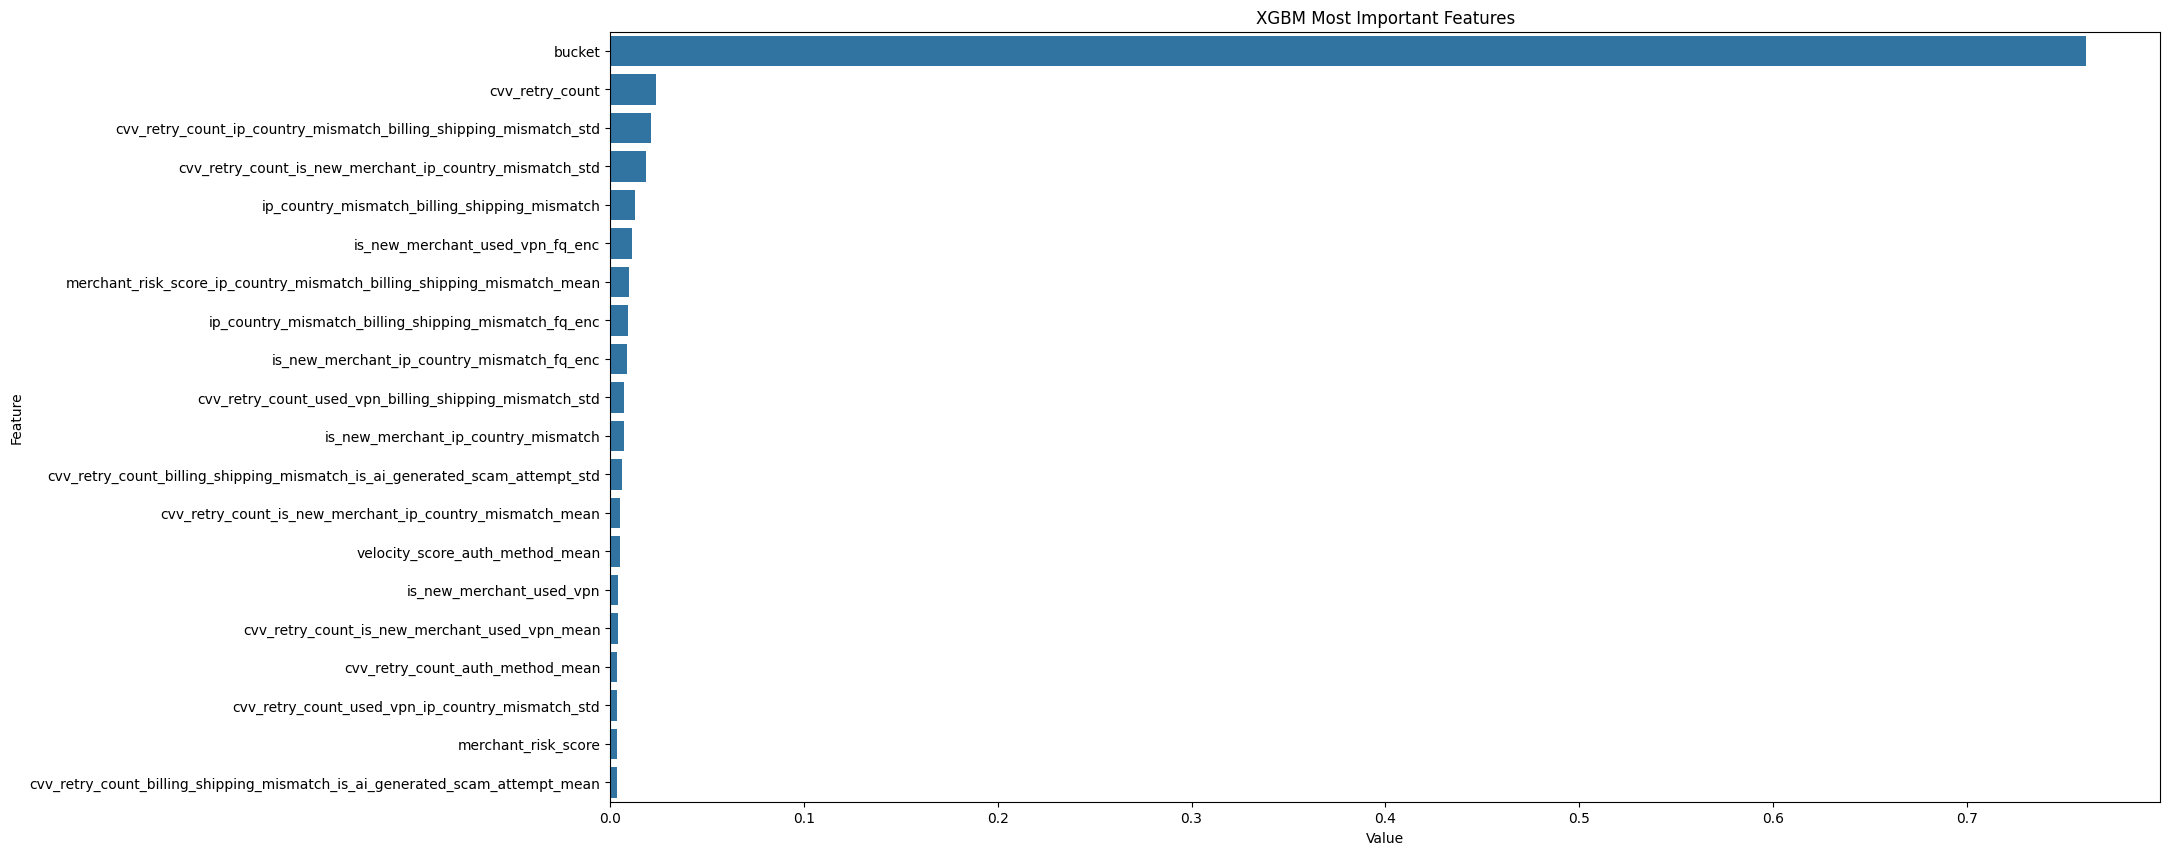

In [25]:
cols = list(X_train.columns)
feature_imp = pd.DataFrame(sorted(zip(clf.feature_importances_,cols)), columns=['Value','Feature'])
plt.figure(figsize=(20, 10))
sns.barplot(x="Value", y="Feature", data=feature_imp.sort_values(by="Value", ascending=False).iloc[:20])
plt.title('XGBM Most Important Features')
#plt.tight_layout()
plt.show()

In [26]:
sub[target] = preds_xgb
sub.to_csv('xgb_submission.csv', index = False)

In [27]:
sub.head()

,id,is_fraud
0,699960,0.0527
1,699961,0.0527
2,699962,0.0527
3,699963,0.0527
4,699964,0.0527


<Axes: >

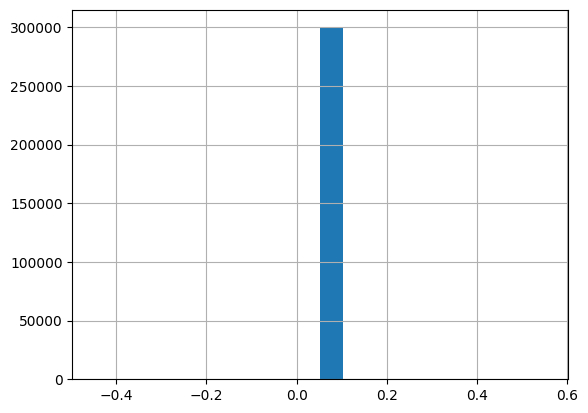

In [28]:
sub[target].hist(bins = 20)